# Esperienza 7 — Costante di tempo del termometro

### Scopo
Si misura la **costante di tempo** $\tau$ del termometro digitale **CI-6605**, cioè il tempo caratteristico con cui la temperatura indicata segue un cambiamento brusco della temperatura dell'ambiente in cui è immerso. La misura si fa in due condizioni:
1. **acqua** (file `7-1.txt`): il termometro, in equilibrio in un thermos a $T_0 \sim 60 \,{}^\circ\mathrm{C}$, viene immerso in un secondo thermos ad acqua a temperatura ambiente $\bar T \sim 25 \,{}^\circ\mathrm{C}$;
2. **aria** (file `7-2.txt`): il termometro, in equilibrio a $T_0$, viene estratto dal thermos e lasciato equilibrare con l'aria, appoggiato sul tavolo.

### Modello (dalla scheda)
Il calore che passa per conduzione attraverso la superficie $S$ del termometro, di conduttanza unitaria $H$, in un tempo $dt$ è
$$\delta Q = -HS\,\big(T(t) - \bar T\big)\,dt,$$
e fa variare la temperatura del termometro, di capacità termica $C$, di $\delta Q = C\,dT$. Uguagliando:
$$C\,dT = HS\,\big(\bar T - T(t)\big)\,dt.$$
Integrando con la condizione iniziale $T(0) = T_0$ si ottiene
$$\boxed{\ T(t) = \bar T - (\bar T - T_0)\,e^{-t/\tau}\ }, \qquad \tau = \frac{C}{HS}. \tag{1}$$
La costante di tempo dipende sia dal termometro ($C$, $S$) sia dal mezzo in cui è immerso, attraverso $H$: in acqua lo scambio di calore è molto più efficace che in aria, quindi ci si aspetta $\tau_\text{acqua} \ll \tau_\text{aria}$.

### Linearizzazione
Per ricavare $\tau$ con un fit lineare (metodo 1 del punto 5 della scheda) si riscrive l'eq. (1) come
$$\bar T - T(t) = (\bar T - T_0)\,e^{-t/\tau} \;\Longrightarrow\; \ln\big|\bar T - T(t)\big| = \ln\big|\bar T - T_0\big| - \frac{t}{\tau}.$$
Il valore assoluto permette di usare la stessa formula sia in raffreddamento ($T_0 > \bar T$) sia in riscaldamento. Nel grafico $y = \ln|\bar T - T|$ in funzione di $t$ i dati devono stare su una retta con pendenza
$$m = -\frac{1}{\tau} \quad\Longrightarrow\quad \tau = -\frac{1}{m}.$$

> Il metodo 2 della scheda (posterior bayesiana dei parametri) non è implementato in questo notebook.

### Preparazione dell'ambiente
Le prime celle importano i moduli e fissano la cartella di lavoro.


In [1]:
import sys
import os

Nel notebook `__file__` non esiste: la cartella di lavoro è quella del notebook (`7/`). I percorsi dei dati (`7/7-1.txt`, ...) e il modulo `info.py` sono relativi a `PP2`. Se `info.py` non si trova nella cartella corrente si sale di un livello, e la cartella si aggiunge a `sys.path` per poter fare `import info`.


In [2]:
# Nel notebook __file__ non esiste: la cartella di lavoro e' quella del notebook.
# I percorsi dei dati (e il modulo info) sono relativi a PP2, quindi ci si sposta li'.
if not os.path.exists("info.py"):
    os.chdir("..")
sys.path.append(os.getcwd())

Il modulo `info` contiene le caratteristiche degli strumenti della postazione. Per il sensore di temperatura CI-6605:
- risoluzione $= 0.05\,{}^\circ\mathrm{C}$;
- accuracy $= 0.5\,{}^\circ\mathrm{C}$.

L'incertezza di tipo B è
$$\sigma_B = \sqrt{\left(\frac{\text{risoluzione}}{\sqrt{12}}\right)^2 + \text{accuracy}^2}.$$
- La **risoluzione** entra divisa per $\sqrt{12}$: l'errore di lettura è distribuito uniformemente su un intervallo largo quanto la risoluzione.
- L'**accuracy** si tiene su ogni lettura. Non si può trattare come un offset da eliminare, perché la curva di risposta del sensore non è nota: non si sa quanto valga punto per punto.


In [3]:
import matplotlib.pyplot as plt
import numpy as np
import info

### Lettura dei file
DataStudio esporta i dati con la **virgola** come separatore decimale (`12,34`), che `numpy` non riconosce come numero. `comma_to_float` sostituisce la virgola con il punto prima della conversione. I file sono in codifica `latin1`, quindi se `loadtxt` passa dei `bytes` vengono prima decodificati.


In [4]:
def comma_to_float(x):
    if isinstance(x, bytes):
        x = x.decode('latin1')
    return float(x.replace(',', '.'))

### Soglie per isolare il transitorio
Il file contiene tre parti: il **plateau iniziale** a $T_0$ (prima dell'immersione), il **transitorio** esponenziale e il **plateau finale** a $\bar T$. Il fit va fatto solo sul transitorio, quindi bisogna stabilire dove inizia e dove finisce.

- `soglia_inizio`: il transitorio inizia al primo punto in cui $|T - T_0|$ supera questa soglia. Serve a escludere il plateau iniziale e il rumore intorno a $T_0$, che non appartengono all'esponenziale. Le soglie sono state scelte guardando i dati di ciascuna prova (0.6 °C in acqua, 0.2 °C in aria): devono stare sopra il rumore del plateau, ma restare abbastanza basse da non perdere l'inizio della discesa.
- `soglia_fine`: il transitorio finisce dopo l'ultimo punto in cui $|T - \bar T|$ supera questa soglia. Da lì in poi $T$ è entro `soglia_fine` da $\bar T$.

La coda va esclusa perché, quando $T \to \bar T$, l'argomento del logaritmo $|\bar T - T|$ diventa confrontabile con il rumore. Il logaritmo allora diverge, l'incertezza $\sigma_y = \sigma/|\bar T - T|$ esplode, e la propagazione al primo ordine non vale più.

`type` contiene le etichette delle due prove, usate nelle stampe.


In [5]:
soglia_inizio_arr = [0.6, 0.2]
soglia_fine_arr = [0.3, 0.3]

type = ["acqua", "aria"]

### Analisi delle due prove
Per ciascuna prova la cella esegue questi passi.

#### 1. Stima di $T_0$ e $\bar T$
$T_0$ e $\bar T$ sono le **medie** dei primi e degli ultimi `n_punti_stima = 50` punti, che stanno sui due plateau a temperatura costante. Bisogna controllare nel grafico che questi 50 punti siano davvero in regime: se contengono un pezzo di transitorio, sia la media sia la dispersione risultano falsate.

#### 2. Incertezza di tipo A sulla singola lettura
Su un plateau la temperatura è costante, quindi la dispersione delle letture misura il rumore della **singola lettura** del termometro:
$$s_{T_0} = \sqrt{\frac{1}{n-1}\sum_k \big(T_k - T_0\big)^2}, \qquad s_{\bar T}\ \text{analoga}.$$
Le due stime si combinano nella deviazione standard combinata (con $n_1 = n_2$ la formula generale $\frac{(n_1-1)s_1^2 + (n_2-1)s_2^2}{n_1+n_2-2}$ si riduce a questa):
$$\sigma_A = \sqrt{\frac{s_{T_0}^2 + s_{\bar T}^2}{2}}.$$
Qui **non** si divide per $\sqrt{n}$: $\sigma_A$ va assegnata a ogni singolo punto $T(t)$ del transitorio, che è una lettura singola e non una media.

#### 3. Incertezza su $T_0$ e $\bar T$
$T_0$ e $\bar T$ sono invece medie di 50 letture, quindi la parte statistica della loro incertezza si riduce di $\sqrt{n}$. La parte B (risoluzione e accuracy) **non** si riduce mediando:
$$\sigma_{T_0} = \sqrt{\left(\frac{s_{T_0}}{\sqrt{n}}\right)^2 + \sigma_B^2}, \qquad \sigma_{\bar T} = \sqrt{\left(\frac{s_{\bar T}}{\sqrt{n}}\right)^2 + \sigma_B^2}.$$

#### 4. Incertezza totale sulla singola lettura
$$\sigma_T = \sqrt{\sigma_A^2 + \sigma_B^2}.$$
Con un'accuracy di 0.5 °C, $\sigma_T$ è dominata dalla parte B.

#### 5. Inizio e fine del transitorio
- `idx_inizio` è il primo indice con $|T - T_0| >$ `soglia_inizio`.
- `idx_fine` è l'indice successivo all'ultimo punto con $|T - \bar T| >$ `soglia_fine`.

I due istanti sono segnati con linee verticali nel primo grafico, per verificare a occhio la selezione.

#### 6. Grafico $T(t)$
Mostra i dati, i livelli $T_0$ e $\bar T$ stimati (tratteggiati) e gli istanti di inizio e fine dell'analisi.

#### 7. Linearizzazione e propagazione delle incertezze
Per ogni punto selezionato:
$$y = \ln\big|\bar T - T\big|.$$
Propagando al primo ordine, $\frac{\partial y}{\partial T} = -\frac{1}{\bar T - T}$ e $\frac{\partial y}{\partial \bar T} = \frac{1}{\bar T - T}$, quindi
$$\sigma_y = \frac{\sqrt{\sigma_T^2 + \sigma_{\bar T}^2}}{\big|\bar T - T\big|}.$$
- Il termine $\sigma_{\bar T}$ c'è perché $\bar T$ compare in ogni punto.
- L'incertezza su $y$ cresce man mano che $T$ si avvicina a $\bar T$: i punti della coda pesano meno nel fit.

#### 8. Fit lineare pesato
`np.polyfit(t, y, 1, w=1/sigma_y, cov='unscaled')` esegue il fit ai minimi quadrati con pesi $1/\sigma_y$. Con `cov='unscaled'` la matrice di covarianza dipende solo dalle $\sigma_y$ assegnate, senza riscalarla per $\chi^2/\text{gdl}$.

La costante di tempo e la sua incertezza si ricavano propagando da $m$:
$$\tau = -\frac{1}{m}, \qquad \sigma_\tau = \left|\frac{d\tau}{dm}\right|\sigma_m = \frac{\sigma_m}{m^2}.$$

#### 9. Intercetta e riferimento $\ln|\bar T - T_0|$
Nel secondo grafico la linea blu tratteggiata (con la sua fascia a $1\sigma$) è
$$y_0 = \ln\big|\bar T - T_0\big|, \qquad \sigma_{y_0} = \frac{\sqrt{\sigma_{T_0}^2 + \sigma_{\bar T}^2}}{\big|\bar T - T_0\big|}.$$
Nel fit però $t$ è il tempo assoluto dell'acquisizione, non il tempo dall'immersione. Se l'immersione avviene all'istante $t_\text{imm}$, la retta attesa è
$$y = \ln\big|\bar T - T_0\big| - \frac{t - t_\text{imm}}{\tau} \;\Longrightarrow\; q = y_0 + \frac{t_\text{imm}}{\tau}.$$
L'intercetta $q$ quindi **non** coincide con $y_0$. La retta di fit deve passare per $y_0$ all'istante dell'immersione, non a $t = 0$.


Stima in acqua: 

T0 stimata: 58.62 ± 0.500 | Tbar stimata: 27.39 ± 0.500
s (T0): 0.062 | s (Tbar): 0.025 | sigma_A usata: 0.047
sigma_B: 0.500 | sigma totale: 0.502
Inizio misura a t=32.66 | Fine misura a t=53.88


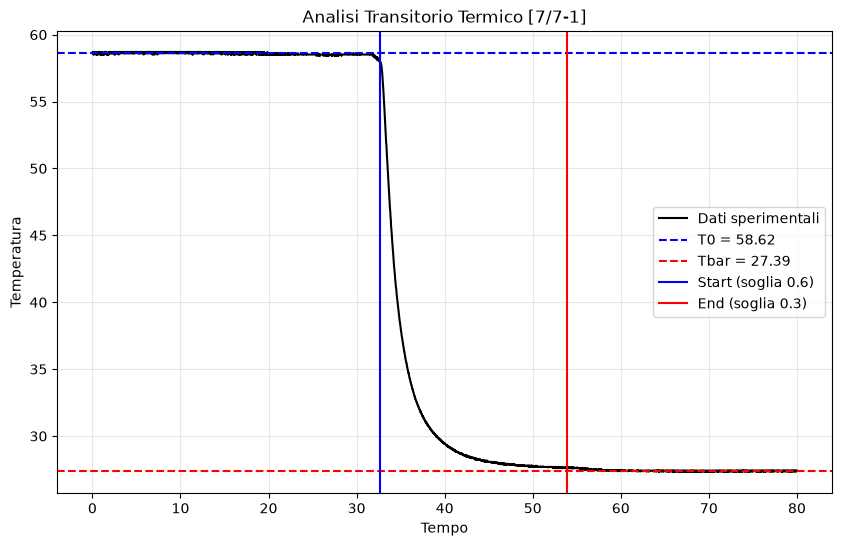

Coefficiente angolare (m): -0.3945 ± 0.0020 | Tau stimato: 2.5349 ± 0.0132
Intercetta (q): 16.3164 ± 0.0693
ln(|Tbar - T0|) = 3.4412 ± 0.0227


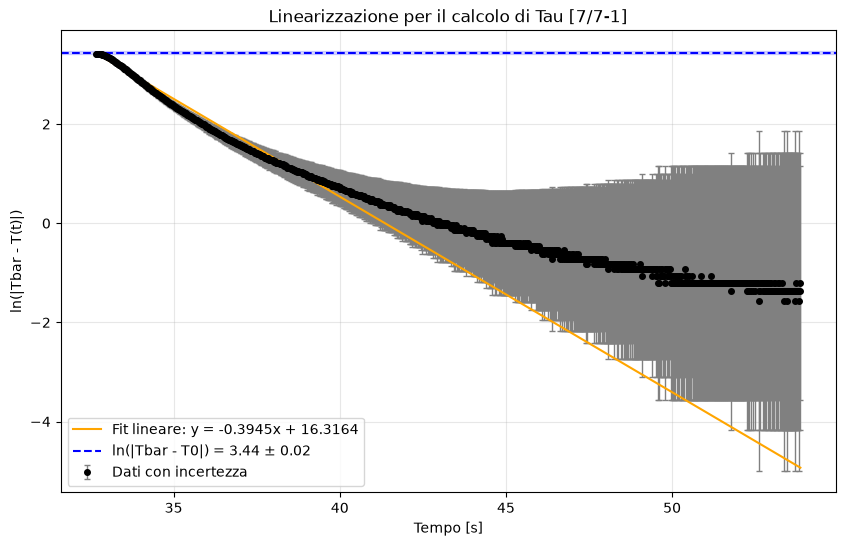


Stima in aria: 

T0 stimata: 56.96 ± 0.500 | Tbar stimata: 26.37 ± 0.500
s (T0): 0.046 | s (Tbar): 0.025 | sigma_A usata: 0.037
sigma_B: 0.500 | sigma totale: 0.502
Inizio misura a t=32.98 | Fine misura a t=475.12


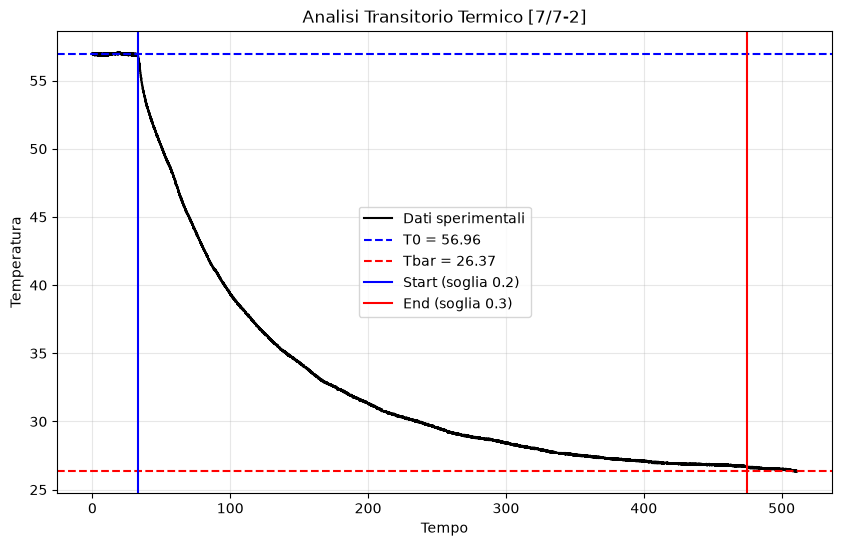

Coefficiente angolare (m): -0.0106 ± 0.0000 | Tau stimato: 94.2537 ± 0.0925
Intercetta (q): 3.6848 ± 0.0010
ln(|Tbar - T0|) = 3.4208 ± 0.0231


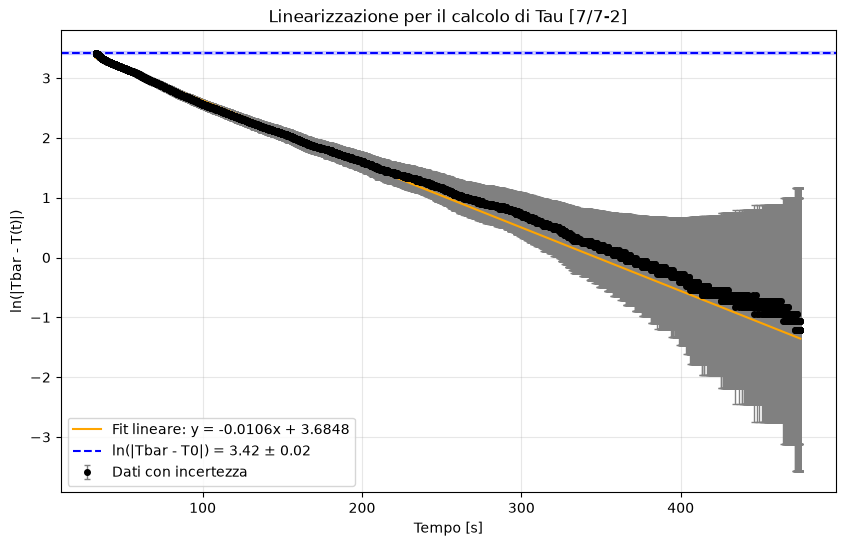

In [ ]:
for i in range(1, 3):
    file = f"7/data/7-{i}"
    t, T = np.loadtxt(f"{file}.txt", unpack=True, skiprows=2, encoding='latin1', converters={0: comma_to_float, 1: comma_to_float})

    soglia_inizio = soglia_inizio_arr[i - 1]
    soglia_fine = soglia_fine_arr[i - 1]

    #STIMO T0 E TBAR
    n_punti_stima = 50

    T_plateau_iniziale = T[:n_punti_stima]
    T_plateau_finale = T[-n_punti_stima:]

    T0 = np.average(T_plateau_iniziale)
    Tbar = np.average(T_plateau_finale)

    #INCERTEZZA DI TIPO A SULLA SINGOLA LETTURA (dispersione a temperatura costante)
    s_T0 = np.std(T_plateau_iniziale, ddof=1)
    s_Tbar = np.std(T_plateau_finale, ddof=1)
    sigma_a_temperatura = np.sqrt((s_T0**2 + s_Tbar**2) / 2)

    #INCERTEZZA SULLE MEDIE T0 E TBAR (tipo A della media + tipo B, che mediando non si riduce)
    sigma_T0 = np.sqrt((s_T0 / np.sqrt(n_punti_stima))**2 + info.sigma_b_temperatura_CI6605**2)
    sigma_Tbar = np.sqrt((s_Tbar / np.sqrt(n_punti_stima))**2 + info.sigma_b_temperatura_CI6605**2)

    #INCERTEZZA TOTALE SULLA SINGOLA LETTURA
    sigma_temperatura = np.sqrt(sigma_a_temperatura**2 + info.sigma_b_temperatura_CI6605**2)
    
    #CERCO PUNTI DI INIZIO / FINE DEL TRANSITORIO
    indici_inizio = np.where(np.abs(T - T0) > soglia_inizio)[0]
    idx_inizio = indici_inizio[0] if len(indici_inizio) > 0 else 0
    tempo_inizio = t[idx_inizio]

    indici_fuori_regime = np.where(np.abs(T - Tbar) > soglia_fine)[0]
    if len(indici_fuori_regime) > 0:
        idx_fine = indici_fuori_regime[-1] + 1  
    else:
        idx_fine = len(t) - 1

    tempo_fine = t[idx_fine]
    
    print(f"Stima in {type[i - 1]}: \n")    
    print(f"T0 stimata: {T0:.2f} ± {sigma_T0:.3f} | Tbar stimata: {Tbar:.2f} ± {sigma_Tbar:.3f}")
    print(f"s (T0): {s_T0:.3f} | s (Tbar): {s_Tbar:.3f} | sigma_A usata: {sigma_a_temperatura:.3f}")
    print(f"sigma_B: {info.sigma_b_temperatura_CI6605:.3f} | sigma totale: {sigma_temperatura:.3f}")
    print(f"Inizio misura a t={tempo_inizio} | Fine misura a t={tempo_fine}")

    #PLOTTO I RISULTATI
    plt.figure(figsize=(10, 6))
    plt.plot(t, T, label='Dati sperimentali', color='black')

    plt.axhline(T0, color='blue', linestyle='--', label=f'T0 = {T0:.2f}')
    plt.axhline(Tbar, color='red', linestyle='--', label=f'Tbar = {Tbar:.2f}')

    plt.axvline(tempo_inizio, color='blue', linestyle='-', label=f'Start (soglia {soglia_inizio})')
    plt.axvline(tempo_fine, color='red', linestyle='-', label=f'End (soglia {soglia_fine})')

    plt.legend()
    plt.title(f"Analisi Transitorio Termico [{file}]")
    plt.xlabel("Tempo")
    plt.ylabel("Temperatura")
    plt.grid(True, alpha=0.3)
    plt.savefig(f"{file}_analisi_transitorio.png", dpi = 300)
    plt.show()

    #PLOTTO IN FORMA LOGARITMICA

    # Filtriamo i dati
    t_per_analisi = t[idx_inizio:idx_fine]
    T_per_analisi = T[idx_inizio:idx_fine]

    x = t_per_analisi
    
    argomento_log = np.abs(Tbar - T_per_analisi)
    y = np.log(argomento_log)

    sigma_y = np.sqrt(sigma_temperatura**2 + sigma_Tbar**2) / argomento_log
            
    coefficienti, matrice_cov = np.polyfit(t_per_analisi, y, deg=1, w=1/sigma_y, cov='unscaled')

    incertezze = np.sqrt(np.diag(matrice_cov))

    m, q = coefficienti
    errore_m, errore_q = incertezze

    tau = -1 / m
    errore_tau = errore_m / m**2
    print(f"Coefficiente angolare (m): {m:.4f} ± {errore_m:.4f} | Tau stimato: {tau:.4f} ± {errore_tau:.4f}")
    
    print(f"Intercetta (q): {q:.4f} ± {errore_q:.4f}")

    plt.figure(figsize=(10, 6))
    
    plt.errorbar(t_per_analisi, 
                 y, 
                 yerr=sigma_y, 
                 fmt='o', 
                 color='black', 
                 markersize = 4,
                 ecolor='gray', 
                 elinewidth=1, 
                 capsize=2, 
                 label='Dati con incertezza'
                 )
    
    plt.plot(t_per_analisi, 
             m * t_per_analisi + q, 
             '-', 
             label=f'Fit lineare: y = {m:.4f}x + {q:.4f}', 
             color='orange'
             )

    y0 = np.log(np.abs(Tbar - T0))
    sigma_y0 = np.sqrt(sigma_T0**2 + sigma_Tbar**2) / np.abs(Tbar - T0)
    print(f"ln(|Tbar - T0|) = {y0:.4f} ± {sigma_y0:.4f}")
    plt.axhline(y0, 
                color='blue', 
                linestyle='--', 
                label=f'ln(|Tbar - T0|) = {y0:.2f} ± {sigma_y0:.2f}'
                )
    plt.axhspan(y0 - sigma_y0, y0 + sigma_y0, color='blue', alpha=0.15)

    plt.legend()
    plt.title(f"Linearizzazione per il calcolo di Tau [{file}]")
    plt.xlabel("Tempo [s]")
    plt.ylabel("ln(|Tbar - T(t)|)")
    plt.grid(True, alpha=0.3)
    plt.savefig(f"{file}_linearizzazione_per_tau.png", dpi = 300)
    plt.show()

       
    print("")

### Confronto tra acqua e aria
Il punto 6 della scheda chiede di confrontare le due costanti di tempo e motivarne la differenza. Dall'eq. (1), $\tau = C/(HS)$:
- $C$ e $S$ sono quelle del termometro e restano uguali nelle due prove;
- cambia solo la **conduttanza unitaria $H$** tra la superficie del termometro e il mezzo.

L'acqua ha conducibilità termica e capacità termica molto maggiori dell'aria, e trasferisce calore per conduzione e convezione molto più efficacemente. Quindi $H_\text{acqua} \gg H_\text{aria}$, e di conseguenza $\tau_\text{acqua} \ll \tau_\text{aria}$. Il rapporto tra le due costanti di tempo stima direttamente il rapporto $H_\text{acqua}/H_\text{aria}$:
$$\frac{\tau_\text{aria}}{\tau_\text{acqua}} = \frac{H_\text{acqua}}{H_\text{aria}}.$$

In aria entrano anche altri effetti da discutere:
- l'acqua rimasta sulla punta, che evapora e raffredda (per questo la scheda raccomanda di asciugarla rapidamente);
- il contatto con il tavolo, che aggiunge conduzione.
